## **Reflections (week 5 - 8)**   
## **Name : Roozbeh Khodayari**

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.neighbors import NearestNeighbors

### **Homework Reflection 5**

**1. Draw a diagram for the following negative feedback loop:**

- Sweating causes body temperature to decrease.  High body temperature causes sweating.

- A negative feedback loop means that one thing increases another while the second thing decreases the first.

- Remember that we are using directed acyclic graphs where two things cannot directly cause each other.

Because a directed acyclic graph (DAG) cannot contain cycles, I would represent the negative feedback loop across time.  

A higher body temperature at time (t) causes more sweating at time (t+1). Increased sweating then causes body temperature to decrease at time (t+2).  

A simple diagram would be:  

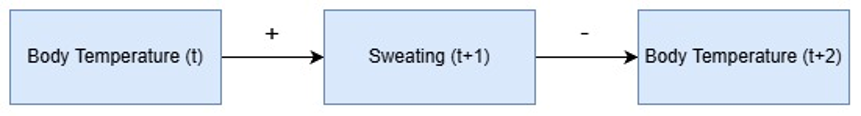 

The positive sign (+) means that higher body temperature increases sweating, while the negative sign (−) means that more sweating decreases body temperature. This keeps the graph acyclic while showing the negative feedback loop over time.


**2. Describe an example of a positive feedback loop.  This means that one thing increases another while the second things also increases the first.**

One example of a positive feedback loop is a popular social media post. When a post gets more likes, it may be shown to more people. As more people see the post, it can receive even more likes.

This creates a positive feedback loop because more likes increase the visibility of the post, and more visibility can lead to even more likes.

**3. Draw a diagram for the following situation:**

Lightning storms frighten away deer and bears, decreasing their population, and cause flowers to grow, increasing their population.
Bears eat deer, decreasing their population.
Deer eat flowers, decreasing their population.

Write a dataset that simulates this situation.  (Show the code.) Include noise / randomness in all cases.

Identify a backdoor path with one or more confounders for the relationship between deer and flowers.

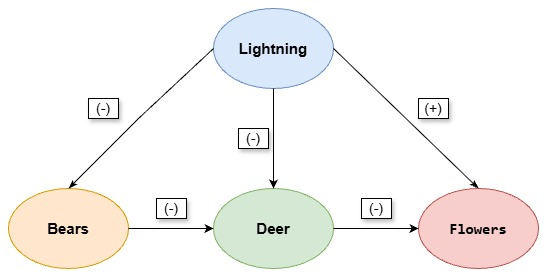

The causal diagram is shown above. Lightning storms decrease the bear and deer populations, while increasing the flower population. Bears also decrease the deer population, and deer decrease the flower population.

To simulate this situation, I created 1,000 observations. I used random values for lightning storms and added random noise when generating the bear, deer, and flower populations.

In [2]:
np.random.seed(42)
n = 1000

# 1 = lightning storm, 0 = no lightning storm
lightning = np.random.binomial(1, 0.3, n)

# Lightning decreases bears
bears = 50 - 15 * lightning + np.random.normal(0, 5, n)

# Lightning and bears decrease deer
deer = (100- 20 * lightning- 0.5 * bears+ np.random.normal(0, 10, n))

# Lightning increases flowers, while deer decrease flowers
flowers = (200+ 30 * lightning- 0.8 * deer+ np.random.normal(0, 15, n))

# Prevent negative population values
bears = np.maximum(bears, 0)
deer = np.maximum(deer, 0)
flowers = np.maximum(flowers, 0)

df = pd.DataFrame({"Lightning": lightning,"Bears": bears,"Deer": deer,"Flowers": flowers})

df.head()

,Lightning,Bears,Deer,Flowers
0,0,50.888505,60.492573,164.723698
1,1,28.323278,65.007305,168.247677
2,1,36.900989,46.502302,174.750146
3,0,53.052929,81.074095,119.510058
4,0,52.798952,74.424921,133.152019


For the relationship between deer and flowers, one backdoor path is:

**Deer ← Lightning → Flowers**

Lightning is a confounder because it affects both the deer population and the flower population.  

Another backdoor path is **Deer ← Bears ← Lightning → Flowers**. 

Because lightning affects both deer and flowers, ignoring it could bias our estimate of how deer affect flowers. Controlling for lightning would block the backdoor paths identified above.

**4. Draw a diagram for a situation of your own invention.  The diagram should include at least four nodes, one confounder, and one collider.**  

Be sure that it is acyclic (no loops).  Which node would say is most like a treatment (X)?  Which is most like an outcome (Y)?

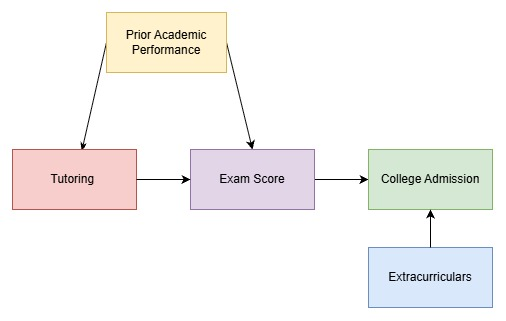

In this example, I examine the effect of **Tutoring** on **Exam Score**. I consider **Tutoring** to be the treatment (X) and **Exam Score** to be the outcome (Y).

**Prior Academic Performance** is a confounder because it can affect both whether a student receives tutoring and how well the student performs on the exam. This creates the path:

**Tutoring ← Prior Academic Performance → Exam Score**

**College Admission** is a collider because it is affected by both **Exam Score** and **Extracurriculars**. This creates the path:

**Exam Score → College Admission ← Extracurriculars**

The diagram is acyclic because the arrows move in one direction and do not form any loop.

### **Homework Reflection 6**

**1. What is a potential problem with computing the Marginal Treatment Effect simply by comparing each untreated item to its counterfactual and taking the maximum difference?**   

(Hint: think of statistics here.  Consider that only the most extreme item ends up being used to estimate the MTE.  That's not necessarily a bad thing; the MTE is supposed to come from the untreated item that will produce the maximum effect.  But there is nevertheless a problem.)
Possible answer: We are likely to find the item with the most extreme difference, which may be high simply due to randomness.
(Please explain / justify this answer, or give a different one if you can think of one.)

A potential problem is that the maximum difference may be extreme partly because of random variation in the data.  

Since we compare many untreated items and only keep the largest effect, we are more likely to select an unusually high value by chance.   

This could make the estimated MTE larger than the true effect and less stable across different samples.

**2. Propose a solution that remedies this problem and write some code that implements your solution.  It's very important here that you clearly explain what your solution will do.** 

Possible answer: maybe we could take the 90th percentile of the treatment effect and use it as a proxy for the Marginal Treatment Effect. (Either code this answer or choose a different one.)

**Primary solution: 90th percentile**  

One possible solution is to use the 90th percentile of the estimated treatment effects instead of using the single maximum value.  

The maximum can be unusually high just because of random variation in one observation.  

The 90th percentile still represents a relatively large treatment effect, but it is less dependent on one extreme value.  

Therefore, I would use the 90th percentile as a proxy for the Marginal Treatment Effect.


In [ ]:
# Load the data
df = pd.read_csv("../data/homework_6.1.csv")

# Separate treated and untreated items
treated = df[df["X"] == 1]
untreated = df[df["X"] == 0]

# Find the nearest treated match for each untreated item using Z
nn = NearestNeighbors(n_neighbors=1)
nn.fit(treated[["Z"]])

_, idx = nn.kneighbors(untreated[["Z"]])

# Estimate the treatment effect for each untreated item
untreated_effects = (treated.iloc[idx.flatten()]["Y"].to_numpy()- untreated["Y"].to_numpy())

# Use the 90th percentile instead of the maximum
mte_proxy = np.percentile(untreated_effects, 90)

print("90th percentile estimate:", mte_proxy)

90th percentile estimate: 1.9279622855613059


**Additional stability check: Bootstrap resampling**  

I would also use bootstrap resampling as a stability check.  

After estimating the treatment effect for each untreated item, I would repeatedly resample these effects with replacement and calculate the 90th percentile for each bootstrap sample.  

If the bootstrap estimates are fairly similar, this gives more confidence that the result is not being driven by one unusual observation.  

The bootstrap does not completely remove the uncertainty, but it helps show how stable the estimate is across different samples.

In [4]:
# Bootstrap the 90th percentile to check its stability
bootstrap_estimates = []

for _ in range(1000):
    sample = np.random.choice(untreated_effects,size=len(untreated_effects),replace=True)

    bootstrap_estimates.append(np.percentile(sample, 90))

bootstrap_estimate = np.mean(bootstrap_estimates)

print("Average bootstrap estimate:", bootstrap_estimate)
print("Bootstrap standard deviation:", np.std(bootstrap_estimates))

Average bootstrap estimate: 1.9268481531050448
Bootstrap standard deviation: 0.017005415589348708


The average bootstrap estimate (about 1.927) was very close to the original 90th-percentile estimate (about 1.928), and the bootstrap standard deviation was small (about 0.017).  

This suggests that the estimate was fairly stable across these resamples.

### **Homework Reflection 7**


**1. Create a linear regression model involving a confounder that is left out of the model.  Show whether the true correlation between X and Y is overestimated, underestimated, or neither.**   

Explain in words why this is the case for the given coefficients you have chosen.

In [18]:
# 1. Generate synthetic data
rng = np.random.default_rng(42)
n = 10000

W = rng.normal(0, 1, n)
error_x = rng.normal(0, 1, n)
error_y = rng.normal(0, 1, n)

X = W + error_x
Y = X + 2 * W + error_y

# 2. Regression without the confounder W
model_omitted = sm.OLS(Y, sm.add_constant(X)).fit()

# 3. Regression including the confounder W
X_full = sm.add_constant(np.column_stack([X, W]))
model_full = sm.OLS(Y, X_full).fit()

# 4. Compare regression coefficients
print("Regression Coefficients:")
print(f"True coefficient of X: 1.000")
print(f"Without W: {model_omitted.params[1]:.3f}")
print(f"With W: {model_full.params[1]:.3f}")

# 5. Simple correlation between X and Y
raw_corr = np.corrcoef(X, Y)[0, 1]

# 6. Partial correlation controlling for W
residual_X = sm.OLS(X, sm.add_constant(W)).fit().resid
residual_Y = sm.OLS(Y, sm.add_constant(W)).fit().resid

partial_corr = np.corrcoef(residual_X, residual_Y)[0, 1]

# 7. Compare correlations
print("\nCorrelations:")
print(f"Simple correlation: {raw_corr:.3f}")
print(f"Partial correlation: {partial_corr:.3f}")


Regression Coefficients:
True coefficient of X: 1.000
Without W: 1.994
With W: 0.988

Correlations:
Simple correlation: 0.849
Partial correlation: 0.703


I created a linear regression model with a confounder W, using X = W + u and Y = X + 2W + e, where u and e are independent random errors.  
W is a confounder because it affects both X and Y. I compared two regression models, one with W and one without it.

The true coefficient of X is 1. When W was included, the estimated coefficient was about 0.99, but when W was omitted, it increased to about 1.99.  
I also compared the correlations. The simple correlation between X and Y was about 0.85, while the partial correlation after controlling for W was about 0.70.

This shows that omitting W overestimates the relationship between X and Y.  
Since W has a positive effect on both X and Y, removing it causes the regression to incorrectly attribute part of W's effect on Y to X. This creates a positive omitted variable bias.

**2. Perform a linear regression analysis in which one of the coefficients is zero, e.g.**

W = [noise]  
X = [noise]  
Y = 2 * X + [noise]

And compute the p-value of a coefficient - in this case, the coefficient of W.  
(This is the likelihood that the estimated coefficient would be as high or low as it is, given that the actual coefficient is zero.)  
If the p-value is less than 0.05, this ordinarily means that we judge the coefficient to be nonzero (incorrectly, in this case.)  
Run the analysis 1000 times and report the best (smallest) p-value.  
If the p-value is less than 0.05, does this mean the coefficient actually is nonzero?  What is the problem with repeating the analysis?

In [20]:
rng = np.random.default_rng(42)

n = 200
trials = 1000
p_values = []

for _ in range(trials):

    # Generate independent variables and noise
    X = rng.normal(0, 1, n)
    W = rng.normal(0, 1, n)
    error = rng.normal(0, 1, n)

    # True model: W has no effect on Y
    Y = 2 * X + error

    # Fit regression including both X and W
    features = sm.add_constant(np.column_stack([X, W]))
    model = sm.OLS(Y, features).fit()

    # Save the p-value for W
    p_values.append(model.pvalues[2])

# Find the smallest p-value across 1000 regressions
min_p = np.min(p_values)

# Count how many tests were significant at 0.05
false_positives = np.sum(np.array(p_values) < 0.05)
print(f"Smallest p-value for W: {min_p:.6f}")
print(f"Number of p-values below 0.05: {false_positives}")

Smallest p-value for W: 0.000539
Number of p-values below 0.05: 44


I generated random data using Y = 2X + e, where X, W, and e are independent. The true coefficient of W is zero, but I included W in the regression to test whether it would appear statistically significant.

I repeated the analysis 1,000 times and recorded the p-value of W in each regression. The smallest p-value was approximately 0.00054, and 44 out of 1,000 tests had p-values below 0.05.

This does not mean W actually affects Y, since its true coefficient is zero. The problem is that repeating the analysis many times increases the chance of finding a statistically significant result just by random chance.  
If we only report the smallest p-value, we may incorrectly conclude that W has an effect on Y. This is a multiple testing problem and can lead to false positives.

### **Homework Reflection 8**


Include the code you used to solve Week 8's coding quiz problems and write about the obstacles / challenges / insights you encountered while solving them.

In [ ]:
# import necessary libraries
import statsmodels.api as sm
from statsmodels.formula.api import ols
import pandas as pd
import numpy as np
from scipy.spatial.distance import mahalanobis

#### Question 1 – Inverse Probability Weighting (IPW)

In [2]:
df = pd.read_csv("../data/homework_8.1.csv")

Z = sm.add_constant(df[["Z"]])
model = sm.Logit(df["X"], Z).fit()

df["p"] = model.predict(Z)

treated = df[df["X"] == 1]
control = df[df["X"] == 0]

treated_mean = np.average(treated["Y"], weights=1 / treated["p"])
control_mean = np.average(control["Y"], weights=1 / (1 - control["p"]))

ate = treated_mean - control_mean
print(ate)

Optimization terminated successfully.
         Current function value: 0.604614
         Iterations 5
2.2680432299497104


Explanation and insight:

In this question, I used inverse probability weighting to estimate the average treatment effect (ATE). First, I fitted a logistic regression model to estimate the probability of receiving treatment based on the confounder Z. Then, I assigned weights of 1/p to treated observations and 1/(1-p) to control observations. Finally, I calculated the difference between the two weighted outcome averages. My estimated ATE was approximately 2.27.

The main insight was understanding why we use different weights for the two groups. IPW gives more weight to observations that are less likely to be in their observed treatment group, helping make the groups more comparable.

#### Question 2 – Calculating Propensity Scores

In [3]:
print(df["p"].head(3))

0    0.841702
1    0.585325
2    0.712446
Name: p, dtype: float64


Explanation and insight:

This question asked for the propensity scores of the first three observations. Since I had already fitted the logistic regression model in Question 1, I used its predicted probabilities instead of building another model.

The first three estimated propensity scores were approximately 0.842, 0.585, and 0.712. I learned that a propensity score represents the probability of receiving treatment based on the observed confounders. It does not tell us whether someone actually received treatment. For example, an untreated observation can still have a high propensity score.

#### Question 3 – Mahalanobis Distance Matching

In [5]:
df2 = pd.read_csv("../data/homework_8.2.csv")

treated = df2[df2["X"] == 1]
control = df2[df2["X"] == 0]

Z_t = treated[["Z1", "Z2"]].to_numpy()
Z_c = control[["Z1", "Z2"]].to_numpy()
VI = np.linalg.inv(np.cov(df2[["Z1", "Z2"]].to_numpy().T))

matches = [np.argmin([mahalanobis(t, c, VI)for c in Z_c]) for t in Z_t]
effect = np.mean(treated["Y"].to_numpy()- control["Y"].to_numpy()[matches])

print(effect)

3.437678997911326


Explanation and challenges:

In this question, I used Mahalanobis distance to find the nearest control observation for each treated observation based on Z1 and Z2. Unlike Euclidean distance, Mahalanobis distance accounts for the variance and correlation between the matching variables. I calculated the inverse covariance matrix and used `argmin()` to identify the nearest control for each treated observation.

After finding the matches, I calculated the difference in outcomes between each treated observation and its matched control, then averaged these differences. This estimates the treatment effect for the treated group (ATT). The estimated ATT was approximately 3.44. This means that, on average, the treated observations had outcomes about 3.44 units higher than their matched control observations.

One important thing I learned was how matching with replacement works. The same control observation can be selected for multiple treated observations. I also learned how the list of matching indices allows us to compare the outcomes of the correct pairs.

#### Question 4 – Common Support and Matching Distance

In [8]:
nearest_distances = [mahalanobis(t, Z_c[m], VI)for t, m in zip(Z_t, matches)]

worst_idx = np.argmax(nearest_distances)

print("Treated observation:")
print(treated.iloc[worst_idx][["Z1", "Z2"]])
print("============")
print("Nearest control:")
print(control.iloc[matches[worst_idx]][["Z1", "Z2"]])
print("============")
print("Matching distance:")
print(nearest_distances[worst_idx])

Treated observation:
Z1    2.696224
Z2    0.538155
Name: 494, dtype: float64
Nearest control:
Z1    1.519995
Z2   -1.282208
Name: 418, dtype: float64
Matching distance:
1.3830045330353775


Explanation and challenges:

This question was the most challenging for me because I initially misunderstood how to identify the observation with the least common support. I first tried to find the largest Mahalanobis distance directly, but then realized that I needed to find the nearest control for each treated observation before comparing the distances.

I used the matching indices from Question 3 to calculate the distance between each treated observation and its nearest control. Then, I used `argmax()` to find the treated observation with the largest nearest-control distance. The largest nearest-control Mahalanobis distance was approximately 1.383, for treated observation 494 matched with control observation 418. This was the weakest match among the treated observations based on the distance measure, suggesting relatively poor overlap for this observation.

This helped me understand that common support is not just about finding a match. A matching algorithm can always select the nearest available control, even if that control is still far away. Therefore, a nearest match is not necessarily a good match.

Overall Challenges and Insights

One of my main challenges this week was understanding the matching logic, especially when using Mahalanobis distance. At first, I confused the order of the minimum and maximum distances. I learned that we first need to find the nearest control for each treated observation, and then identify the treated observation whose nearest control is the farthest away. Breaking the problem into smaller steps helped me understand the question and write the code correctly.

Another important insight was understanding common support. I realized that finding a nearest match does not always mean finding a good match. Even the closest control observation might still be very different from the treated observation, which can lead to biased estimates. I also learned how propensity scores and inverse probability weighting can help make treatment and control groups more comparable.

Overall, this week's coding quiz helped me better understand the differences between matching and weighting methods. My biggest challenge was translating the questions into the correct steps in Python, rather than just understanding the formulas. Working through each problem step by step helped me improve both my coding skills and my understanding of causal inference. However, the lessons covered many more topics, including kernel matching, caliper matching, coarsened exact matching, entropy balancing, balance checking, stratification tests, regression adjustment, doubly robust estimation, and bootstrap. The coding quiz focused on only a few of these methods, so I didn't get a chance to practice many of the others. I wish the quiz had included more hands-on exercises covering these topics, because understanding the concepts without applying them in Python was challenging for me.